# **Problem Set 3**
## CHEM 5541 - Chemical Dynamics
### *Samuel Arnold*
### *9/18/26*
***

## 1.) Stern-Volmer Analysis

### 1a.)

$$\frac{d[\text{Br}^*]}{dt} = -k_1[\text{Br}^*][\text{HCl}] - k_2[\text{Br}^*][\text{Br}_2]$$

$$\frac{d[\text{Br}^*]}{dt} = -(k_1[\text{HCl}] + k_2[\text{Br}_2])[\text{Br}^*]$$

Since $[\text{Br}^*] << [\text{Br}_2], [\text{HCl}]$, the concentrations of the quenchers can be said to remain constant. Which allows us to create an effective rate constant, $k_{eff}$

$$\frac{d[\text{Br}^*]}{dt} = -k_{eff}[\text{Br}^*]$$

Which through integration:

$$[\text{Br}^*(t)] = e^{-k_{eff}(t-t_0)}$$

$$[\text{Br}^*(t)] = e^{(k_1[\text{HCl}] + k_2[\text{Br}_2])(t-t_0)}$$

### 1b.) 

$$k_{eff} = \frac{1}{\tau} = k_1[\text{HCl}] + k_2[\text{Br}_2]$$

The slope of this plot is $k_1$ with a y-intercept of $k_2[\text{Br}_2]$.

WebIO._IJuliaInit()

k1: 14501.01 m³/(mol*s)
k2: 10110.32 m³/(mol*s)


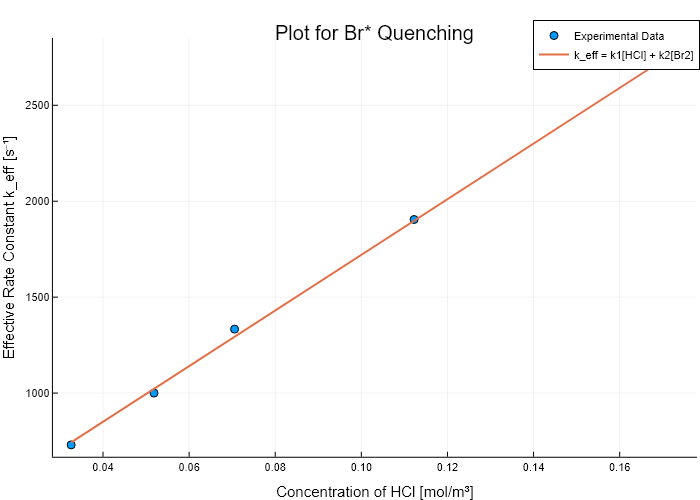

In [ ]:
using Plots

plotly()
default(size=(900, 600))


R = 8.314        # Pa m^3/(mol*K)
T = 300.0        # K

P_br2_torr = [0.5, 0.5, 0.5, 0.5, 0.5]
P_br2_pas = P_br2_torr .* 133.322
conc_br2 = P_br2_pas ./ (R * T)

P_hcl_torr = [0.61, 0.97, 1.32, 2.10, 3.25]
P_hcl_pas = P_hcl_torr .* 133.322
conc_hcl = P_hcl_pas ./ (R * T)

tau_us = [1370, 1000, 750, 525, 360]
k_eff = 1 ./ (tau_us .* 1e-6)

length_conc = length(conc_hcl)
avg_conc = sum(conc_hcl) / length_conc
avg_tau = sum(k_eff) / length_conc

numerator = sum((conc_hcl .- avg_conc) .* (k_eff .- avg_tau))
denominator = sum((conc_hcl .- avg_conc) .^ 2)

k1 = numerator / denominator
intercept = avg_tau - (k1 * avg_conc)

k2 = intercept / conc_br2[1]

conc_range = range(minimum(conc_hcl), maximum(conc_hcl), length=100)
fit_line = k1 .* conc_range .+ intercept

println("k1: ", round(k1, digits=2), " m³/(mol*s)")
println("k2: ", round(k2, digits=2), " m³/(mol*s)")

scatter(
    conc_hcl,
    k_eff,
    xlabel = "Concentration of HCl [mol/m³]",
    ylabel = "Effective Rate Constant k_eff [s⁻¹]",
    title = "Plot for Br* Quenching",
    label = "Experimental Data"
)

plot!(
    conc_range, 
    fit_line,
    label = "k_eff = k1[HCl] + k2[Br2]",
    linewidth = 2
)


***
## 2.) Laplace Transforms



### a.)

$$A \xrightarrow{k_1} B \xrightarrow{k_2} C$$

$$\frac{dA}{dt} = -k_1[A] \hspace{0.75cm} \longrightarrow \hspace{0.75cm} p\mathcal{L}[A] - [A]_0 = -k_1\mathcal{L}[A]$$

$$\frac{dB}{dt} = k_1[A] - k_2[B] \hspace{0.75cm} \longrightarrow \hspace{0.75cm} p\mathcal{L}[B] - [B]_0 = k_1\mathcal{L}[A] - k_2\mathcal{L}[B]$$

$$\frac{dC}{dt} = k_2[B] \hspace{0.75cm} \longrightarrow \hspace{0.75cm} p\mathcal{L}[C] - [C]_0 = k_2\mathcal{L}[B]$$


### b.)

$$\mathcal{L}[A] = \frac{[A]_0}{(p+k_1)}$$

$$[A](t) = [A]_0 e^{-k_1 t}$$

### c.)

$$\mathcal{L}[B] = \frac{k_1 \mathcal{L}[A] + [B]_0}{p + k_2}$$

$$\mathcal{L}[B] = \frac{k_1 \frac{[A]_0}{(p+k_1)} + [B]_0}{p + k_2}$$

$$\mathcal{L}[B] = \frac{k_1 [A]_0+ [B]_0 (p+k_1)}{(p + k_2)(p + k_1)}$$

$$\mathcal{L}[B] = \frac{k_1 [A]_0}{(p + k_2)(p + k_1)} + \frac{[B]_0}{(p + k_2)}$$

$$[B](t) = \frac{k_1 [A]_0}{k_2 - k_1}(e^{-k_1 t} - e^{-k_2 t}) + [B]_0 e^{-k_2 t}$$

if $[B]_0 = 0$

$$[B](t) = \frac{k_1 [A]_0}{k_2 - k_1}(e^{-k_1 t} - e^{-k_2 t})$$

### d.)

$$\mathcal{L}[C] = \frac{k_2\mathcal{L}[B] + [C]_0}{p}$$

$$\mathcal{L}[C] = \frac{k_1 k_2 [A]_0}{p(p + k_2)(p + k_1)} + \frac{k_2[B]_0}{p(p + k_2)} + \frac{[C]_0}{p}$$

$$\mathcal{L}^{-1} \left(\frac{[C]_0}{p} \right) = [C]_0$$

$$\mathcal{L}^{-1} \left(\frac{k_2[B]_0}{p(p+k_2)} \right) = [B]_0(1-e^{-k_2t})$$

Using partial fractions here:

$$\frac{k_1 k_2}{p(p + k_2)(p + k_1)} = \frac{X}{p} + \frac{Y}{p + k_1} + \frac{Z}{p + k_2}$$

$$X = 1 \hspace{0.5cm} Y = -\frac{k_2}{k_2 - k_1} \hspace{0.5cm} Z = \frac{k_1}{k_2 - k_1}$$

$$\frac{k_1 k_2}{p(p + k_2)(p + k_1)} = \frac{1}{p} + -\frac{k_2}{k_2 - k_1} \frac{1}{p + k_1} + \frac{k_1}{k_2 - k_1} \frac{1}{p + k_2}$$

$$\mathcal{L}^{-1} = 1 - \frac{k_2}{k_2 - k_1} e^{-k_1 t} + \frac{k_1}{k_2 - k_1} e^{-k_2 t}$$

$$= 1 - \frac{k_2 e^{-k_1 t} - k_2 e^{-k_2 t}}{k_2 - k_1}$$

$$= [A]_0 \left[ 1 - \frac{k_2 e^{-k_1 t} - k_2 e^{-k_2 t}}{k_2 - k_1} \right]$$

$$[C](t) = [A]_0 \left[ 1 - \frac{k_2 e^{-k_1 t} - k_2 e^{-k_2 t}}{k_2 - k_1} \right] + [B]_0(1-e^{-k_2t}) + [C]_0$$

if $[B]_0 = [C]_0 = 0$

$$[C](t) = [A]_0 \left[ 1 - \frac{k_2 e^{-k_1 t} - k_2 e^{-k_2 t}}{k_2 - k_1} \right]$$

***

## 3.) Consecutive Reactions, Pre-Equilibrium, and Rate Constants

### a.) 

$$A + B \rightleftharpoons AB \xrightarrow{+C} D$$

$$K = \frac{[AB]}{[A][B]}$$

$$\frac{dD}{dt} = -k[AB][C]$$

$$[AB] = K[A][B]$$

which can be subsituted into the ODE

$$\frac{dD}{dt} = kK[A][B][C]$$

with $k_r = kK$

$$R = k_r[A][B][C]$$

For the $T$-dependence of $k_r$, starting with $K$

$$-RT \ln K = \Delta_r H^{\circ} - T\Delta_r S^{\circ}$$

$$\ln K = -\frac{\Delta_r H^{\circ}}{RT} + \frac{\Delta_r S^{\circ}}{R}$$

$$K = e^{-\frac{\Delta_r H^{\circ}}{RT}} \cdot e^{\frac{\Delta_r S^{\circ}}{R}}$$

For $k$ now,

$$k = A e^{-\frac{E_a}{RT}}$$

Such that:

$$k_r = A e^{-\frac{E_a}{RT}} \left(e^{-\frac{\Delta_r H^{\circ}}{RT}} \cdot e^{\frac{\Delta_r S^{\circ}}{R}} \right)$$

$$k_r = A  e^{\frac{\Delta_r S^{\circ}}{R}} \left(e^{-\frac{E_a + \Delta_r H^{\circ}}{RT}} \right)$$

Resulting in:

$$a = A  e^{\frac{\Delta_r S^{\circ}}{R}}$$

and:

$$k_r = a \cdot e^{-\frac{E_a + \Delta_r H^{\circ}}{RT}}$$


### b.)

$$A + B \xrightleftharpoons[k_2]{k_1} C \xrightarrow{k_3} D$$

$$\frac{dD}{dt} = k_3[C]$$

Using SSA for $\frac{dC}{dt} = 0$

$$\frac{dC}{dt} = k_1[A][B] - k_2[C] - k_3[C] = 0$$

$$k_1[A][B] = [C](k_2 + k_3)$$

$$[C] = \frac{k_1[A][B]}{(k_2 + k_3)}$$

Substituting back into the expression of $\frac{dD}{dt}$:

$$\frac{dD}{dt} = \frac{k_3 k_1[A][B]}{(k_2 + k_3)}$$

Defining $k_r \equiv \frac{k_3 k_1}{(k_2 + k_3)}$ to get to the psuedo-second-order rate law:

$$\frac{dD}{dt} = k_r[A][B]$$

If $k_3 \ll k_2$

$$k_r \approx \frac{k_3 k_1}{k_2}$$

$$k_r \approx \frac{A_3 e^{-\frac{E_{a,3}}{RT}} A_1 e^{-\frac{E_{a,1}}{RT}}}{A_2 e^{-\frac{E_{a,2}}{RT}}}$$

$$k_r \approx \frac{A_3 A_1}{A_2} \left(e^{-\frac{E_{a,3} + E_{a,1} - E_{a,2}}{RT}} \right)$$

$$A_r = \frac{A_3 A_1}{A_2}$$

$$E_{a,r} = E_{a,3} + E_{a,1} - E_{a,2}$$

***

## 4.) Unimolecular Reaction with Autocatalysis

### a.)

$$\frac{dA}{dt} = -k_1[A] - k_2[A][B]$$

$$\frac{dB}{dt} = k_1[A] + k_2[A][B]$$

### b.)

$$N = A_0 + B_0$$

The total moles must also be equal when changing, so:

$$\frac{dN}{dt} = \frac{dA}{dt} + \frac{dB}{dt}$$

$$\frac{dN}{dt} = (-k_1[A] - k_2[A][B]) + (k_1[A] + k_2[A][B]) = 0$$

Which further shows that the total moles throughout the reaction does not change.

### c.)

$$\frac{dA}{dt} = rA \left(1 - \frac{A}{K} \right)$$

Need the above equation in terms of $k_1, k_2, A_0, B_0$. $A$ is in the equation, but not $B$, so subsitute that.

$$\frac{dA}{dt} = -k_1[A] - k_2[A] \left[([A]_0 + [B]_0) - [A] \right]$$

$$\frac{dA}{dt} = -k_1[A] - k_2[A] ([A]_0 + [B]_0) + k_2[A]^2$$

$$\frac{dA}{dt} = -(k_1 + k_2([A]_0 + [B]_0))[A] + k_2[A]^2$$

$$\frac{dA}{dt} = -[k_1 + k_2(A_0 + B_0)]A \left(1 - \frac{k_2A}{k_1 + k_2(A_0 + B_0)} \right)$$

Which is of the same form as the original equation such that:

$$r \equiv -[k_1 + k_2(A_0 + B_0)]$$

$$K \equiv \frac{k_1 + k_2(A_0 + B_0)}{k_2}$$

### d.) 

$$A(t) = \frac{K A_0 e^{rt}}{K + A_0 (e^{rt} - 1)}$$

$$A(t) = \frac{\frac{k_1 + k_2(A_0 + B_0)}{k_2} A_0 e^{-[k_1 + k_2(A_0 + B_0)]t}}{\frac{k_1 + k_2(A_0 + B_0)}{k_2} + A_0 (e^{-[k_1 + k_2(A_0 + B_0)]t} - 1)}$$

┌ Warning: Replacing docs for `Plots.plotly_scene_aspect :: Tuple{Plots.Subplot}` in module `Plots`
└ @ Base.Docs docs\Docs.jl:249


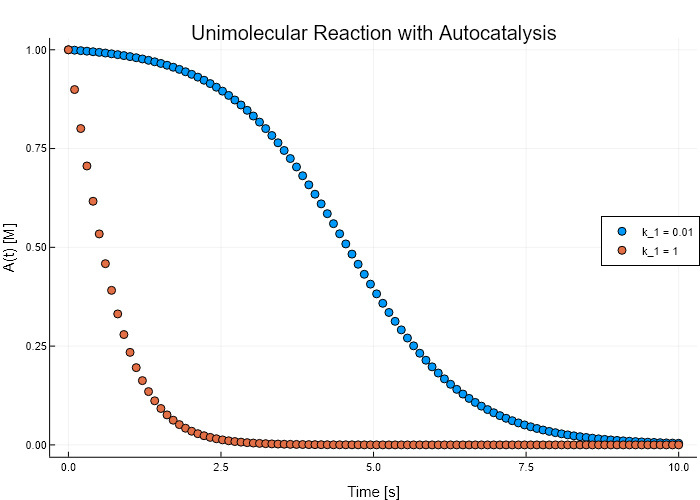

In [12]:
using Plots

plotly()

t_range = range(0, 10, length=100)

k_1 = 0.01      # s^-1
k_2 = 1         # L mol^-1 s^-1
A_0 = 1         # mol/L
B_0 = 0
k_1_comp = 1    # s^-1

K = (k_1 + k_2 * (A_0 + B_0)) / k_2

r = -(k_1 + k_2 * (A_0 + B_0))

A_t = (K * A_0 * exp.(r * t_range)) ./ (K .+ A_0 * (exp.(r * t_range) .- 1))

K_comp = (k_1_comp + k_2 * (A_0 + B_0)) / k_2

r_comp = -(k_1_comp + k_2 * (A_0 + B_0))

A_t_comp = (K_comp * A_0 * exp.(r_comp * t_range)) ./ (K_comp .+ A_0 * (exp.(r_comp * t_range) .- 1))

scatter(
    t_range,
    A_t,
    label="k_1 = 0.01",
    xlabel="Time [s]",
    ylabel="A(t) [M]",
    title="Unimolecular Reaction with Autocatalysis",
    legend=:right
)

scatter!(
    t_range,
    A_t_comp,
    label="k_1 = 1",
    xlabel="Time [s]",
    ylabel="A(t) [M]"
)

When $k_1 \ll k_2$, the autocatalytic pathway dominates and causes a slow decline in $[A]$ as $[B]$ builds up, falling off once $[B]$ is sufficiently high to catalyze enough reactions. When $k_1 = k_2$, the unimolecular route dominates and causes a rapid decline in $[A]$ as the slower $B$ catalyzed pathway does not gain sufficient momentum.

***

## 5.) Simulating Consecutive Reactions

### a.)

$$A\xrightleftharpoons[k_{A2}]{k_{A1}}B\xrightleftharpoons[k_{B2}]{k_{B1}}C$$

51×4 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L)  [C](mol/L) 
     │ Float64  Float64     Float64     Float64    
─────┼─────────────────────────────────────────────
   1 │     0.0    1.0         0.0         0.0
   2 │     1.0    0.8         0.2         0.0
   3 │     2.0    0.68        0.28        0.04
   4 │     3.0    0.6         0.312       0.088
   5 │     4.0    0.5424      0.3248      0.1328
   6 │     5.0    0.49888     0.32992     0.1712
   7 │     6.0    0.465088    0.331968    0.202944
   8 │     7.0    0.438464    0.332787    0.228749
   9 │     8.0    0.417329    0.333115    0.249556
  10 │     9.0    0.400486    0.333246    0.266268
  11 │    10.0    0.387038    0.333298    0.279664
  12 │    11.0    0.37629     0.333319    0.290391
  13 │    12.0    0.367696    0.333328    0.298976
  14 │    13.0    0.360822    0.333331    0.305847
  15 │    14.0    0.355324    0.333332    0.311344
  16 │    15.0    0.350926    0.333333    0.315741
  17 │    16.0    0.347407    0.33

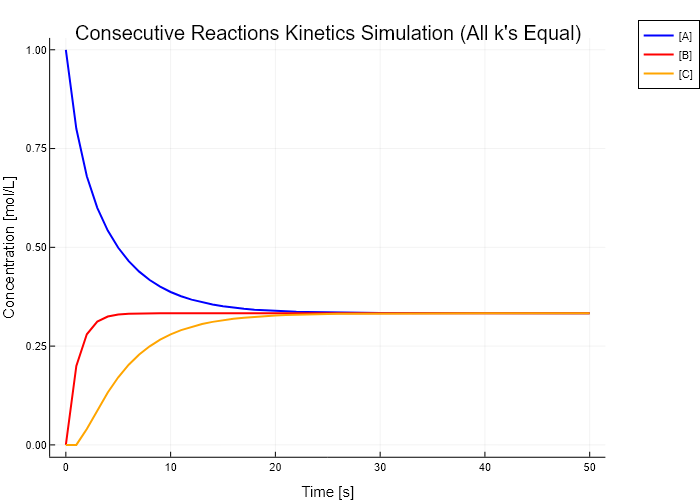

In [11]:
using CSV
using DataFrames
using Plots

function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    C_0 = 0.0         # mol/L
    k_a_1 = 0.2       # s^-1
    k_a_2 = 0.2       # s^-1
    k_b_1 = 0.2       # s^-1
    k_b_2 = 0.2       # s^-1
    delta_t = 1.0     # s
    T = 50            # s


    t_array = []
    A_array = []
    B_array = []
    C_array = []

    A = A_0
    B = B_0
    C = C_0
    t = 0.0

    open("S.Arnold_PS3_Q5ai_output.txt", "w") do io
        write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, C_0=$C_0 mol/L, k_a_1=$k_a_1 s^-1, k_a_2=$k_a_2 s^-1, k_b_1=$k_b_1 s^-1, k_b_2=$k_b_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
        write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\t[C](mol/L)\n")

        while t <= T
            push!(t_array, t)
            push!(A_array, A)
            push!(B_array, B)
            push!(C_array, C)
            
            write(io, "$t\t$A\t$B\t$C\n")
            
            # Rate laws
            dA = (-k_a_1 * A + k_a_2 * B) * delta_t
            dB = (k_a_1 * A + k_b_2 * C - k_b_1 * B - k_a_2 * B) * delta_t
            dC = (-k_b_2 * C + k_b_1 * B) * delta_t
            
            A += dA
            B += dB
            C += dC
            t += delta_t
        end
    end

    df = CSV.read("S.Arnold_PS3_Q5ai_output.txt", DataFrame, delim='\t', comment="#")
    print(df)

    Plots.plot(
        t_array, 
        A_array,
        title="Consecutive Reactions Kinetics Simulation (All k's Equal)",
        label="[A]", 
        xlabel="Time [s]",
        ylabel="Concentration [mol/L]",
        color=:blue, 
        linewidth=2,
        legend=:outertopright
    )

    plot!(
        t_array, 
        B_array, 
        label="[B]", 
        color=:red, 
        linewidth=2
    )

    plot!(
        t_array, 
        C_array, 
        label="[C]", 
        color=:orange, 
        linewidth=2
    )
    
end

kinetics_simulation()

## b.)

500×4 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L)  [C](mol/L) 
     │ Float64  Float64     Float64     Float64    
─────┼─────────────────────────────────────────────
   1 │     0.0  1.0          0.0        0.0
   2 │     0.1  0.99         0.01       0.0
   3 │     0.2  0.9801       0.0198     0.0001
   4 │     0.3  0.970299     0.029403   0.000298
   5 │     0.4  0.960596     0.038812   0.00059203
   6 │     0.5  0.95099      0.0480298  0.00098015
   7 │     0.6  0.94148      0.0570594  0.00146045
   8 │     0.7  0.932065     0.0659036  0.00203104
   9 │     0.8  0.922745     0.0745652  0.00269008
  10 │     0.9  0.913517     0.083047   0.00343573
  11 │     1.0  0.904382     0.0913517  0.0042662
  12 │     1.1  0.895338     0.099482   0.00517972
  13 │     1.2  0.886385     0.107441   0.00617454
  14 │     1.3  0.877521     0.11523    0.00724894
  15 │     1.4  0.868746     0.122853   0.00840124
  16 │     1.5  0.860058     0.130312   0.00962977
  17 │     1.6  0.851458     0.13

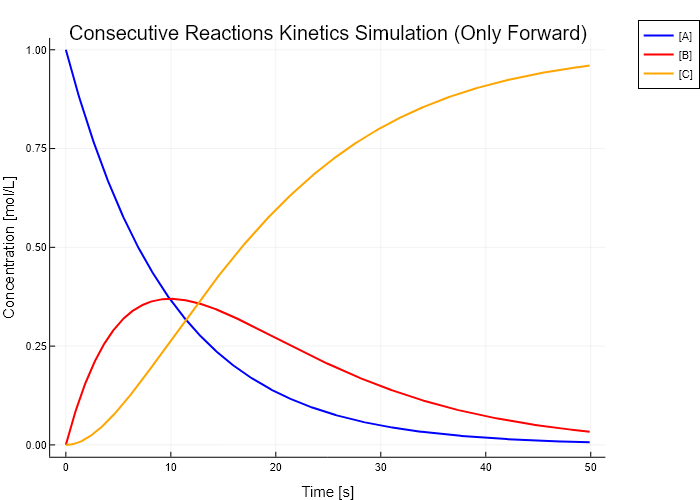

In [10]:
using CSV
using DataFrames
using Plots

function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    C_0 = 0.0         # mol/L
    k_a_1 = 0.1       # s^-1
    k_a_2 = 0.0       # s^-1
    k_b_1 = 0.1       # s^-1
    k_b_2 = 0.0       # s^-1
    delta_t = 0.1     # s
    T = 50            # s


    t_array = []
    A_array = []
    B_array = []
    C_array = []

    A = A_0
    B = B_0
    C = C_0
    t = 0.0

    open("S.Arnold_PS3_Q5aii_output.txt", "w") do io
        write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, C_0=$C_0 mol/L, k_a_1=$k_a_1 s^-1, k_a_2=$k_a_2 s^-1, k_b_1=$k_b_1 s^-1, k_b_2=$k_b_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
        write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\t[C](mol/L)\n")

        while t <= T
            push!(t_array, t)
            push!(A_array, A)
            push!(B_array, B)
            push!(C_array, C)
            
            write(io, "$t\t$A\t$B\t$C\n")
            
            # Rate laws
            dA = (-k_a_1 * A + k_a_2 * B) * delta_t
            dB = (k_a_1 * A + k_b_2 * C - k_b_1 * B - k_a_2 * B) * delta_t
            dC = (-k_b_2 * C + k_b_1 * B) * delta_t
            
            A += dA
            B += dB
            C += dC
            t += delta_t
        end
    end

    df = CSV.read("S.Arnold_PS3_Q5aii_output.txt", DataFrame, delim='\t', comment="#")
    print(df, "\n")

    B_max_row = argmax(df[!, :"[B](mol/L)"])
    
    max_time = df[B_max_row, :"Time(s)"]
    max_val_B = df[B_max_row, :"[B](mol/L)"]
    
    println("-"^50)
    println("\nMaximum of B is ", round(max_val_B, digits=4), " mol/L at Time: ", round(max_time, digits=2), " s\n")
    println("-"^50)
    
    Plots.plot(
        t_array, 
        A_array,
        title="Consecutive Reactions Kinetics Simulation (Only Forward)",
        label="[A]", 
        xlabel="Time [s]",
        ylabel="Concentration [mol/L]",
        color=:blue, 
        linewidth=2,
        legend=:outertopright
    )

    plot!(
        t_array, 
        B_array, 
        label="[B]", 
        color=:red, 
        linewidth=2
    )

    plot!(
        t_array, 
        C_array, 
        label="[C]", 
        color=:orange, 
        linewidth=2
    )
    
end

kinetics_simulation()


k (s^-1)   | Max [B]      | t_B,max (s)    
---------------------------------------------
0.1        | 0.3697       | 9.9            
0.2        | 0.5035       | 6.9            
0.3        | 0.5822       | 5.4            
0.4        | 0.6359       | 4.6            
0.5        | 0.6756       | 4.0            



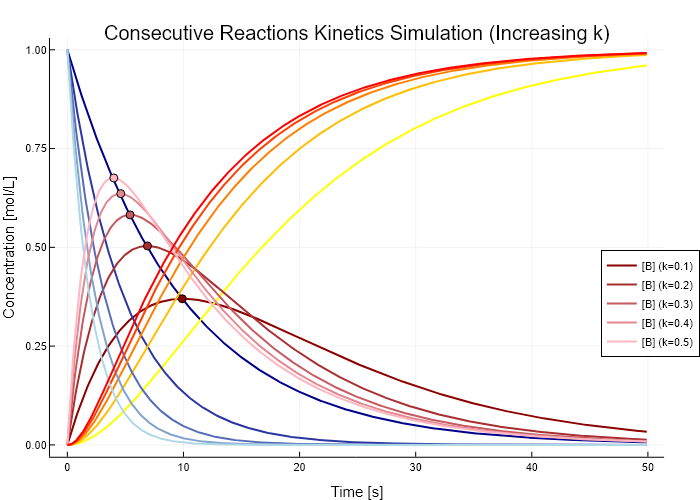

In [9]:
using CSV
using DataFrames
using Plots

function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    C_0 = 0.0         # mol/L
    k_a_1 = 0.1       # s^-1
    k_a_2 = 0.0       # s^-1
    k_b_1 = 0.1       # s^-1
    k_b_2 = 0.0       # s^-1
    delta_t = 0.1     # s
    T = 50            # s
    delta_k = 0.1    # s^-1
    num_steps = 5

    A_colors = palette(:blues, rev = true, num_steps)
    B_colors = palette(:reds, rev = true, num_steps)
    C_colors = palette(:autumn1, rev = true, num_steps)

    initial_plot = Plots.plot(
            title="Consecutive Reactions Kinetics Simulation (Increasing k)",
            xlabel="Time [s]",
            ylabel="Concentration [mol/L]",
            legend=:outerright
    )

    results_str = "\n" * "="^45 * "\n"
    results_str *= rpad("k (s^-1)", 10) * " | " * rpad("Max [B]", 12) * " | " * rpad("t_B,max (s)", 15) * "\n"
    results_str *= "-"^45 * "\n"

    open("S.Arnold_PS3_Q5aiii_output.txt", "w") do io
        write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, C_0=$C_0 mol/L, k_a_1=$k_a_1 s^-1, k_a_2=$k_a_2 s^-1, k_b_1=$k_b_1 s^-1, k_b_2=$k_b_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
        write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\t[C](mol/L)\n")


        for step in 0:(num_steps-1)
            t_array = []
            A_array = []
            B_array = []
            C_array = []

            A = A_0
            B = B_0
            C = C_0
            t = 0.0
            k_a_1_it = k_a_1 + step * delta_k
            # k_b_1_it = k_b_1 + step * delta_k
    
            while t <= T
                push!(t_array, t)
                push!(A_array, A)
                push!(B_array, B)
                push!(C_array, C)
                
                write(io, "$step\t$t\t$A\t$B\t$C\n")
                
                # Rate laws
                dA = (-k_a_1_it * A + k_a_2 * B) * delta_t
                dB = (k_a_1_it * A + k_b_2 * C - k_b_1 * B - k_a_2 * B) * delta_t
                dC = (-k_b_2 * C + k_b_1 * B) * delta_t
                
                A += dA
                B += dB
                C += dC
                t += delta_t
            end

            max_idx = argmax(B_array)
            max_val_B = B_array[max_idx]
            max_time = t_array[max_idx]

            lbl_k = round(k_a_1_it, digits=2) 

            k_str = rpad(string(round(lbl_k, digits=2)), 10)
            b_str = rpad(string(round(max_val_B, digits=4)), 12)
            t_str = rpad(string(round(max_time, digits=2)), 15)
            results_str *= k_str * " | " * b_str * " | " * t_str * "\n"

            current_A_color = A_colors[step + 1]
            current_B_color = B_colors[step + 1]
            current_C_color = C_colors[step + 1]

            plot!(
                initial_plot,
                t_array,
                A_array,
                label="", 
                color=current_A_color, 
                linewidth=2, 
            )

            plot!(
                initial_plot,
                t_array, 
                B_array, 
                label="[B] (k=$lbl_k)", 
                color=current_B_color, 
                linewidth=2, 
            )

            plot!(
                initial_plot,
                t_array, 
                C_array, 
                label="", 
                color=current_C_color, 
                linewidth=2, 
            )

            scatter!(
                initial_plot,
                [max_time],
                [max_val_B],
                color=current_B_color,
                label="", 
                markersize=4
            )
        end
    end

    results_str *= "="^45 * "\n"
    
    println(results_str)
    flush(stdout)
    
    return initial_plot

end

kinetics_simulation()

### c.)


$$B = \frac{k_a}{k_b-k_a}(e^{-k_at} - e^{-k_bt})[A]_0$$

$$\frac{dB}{dt} = \frac{k_a [A]_0}{k_b-k_a} (-k_ae^{-k_at} + k_b e^{-k_bt}) = 0$$

$$\left(\frac{k_b}{k_a} \right) = e^{(k_b - k_a)t}$$

$$t_{max} = \frac{\ln \left(\frac{k_b}{k_a} \right)}{(k_b - k_a)}$$

$$B_{max} = \frac{k_a [A]_0}{k_b-k_a}(e^{-k_at_{max}} - e^{-k_bt_{max}})$$


k_A1     | t_max(Sim)   | t_max(Calc)  | B_max(Sim)   | B_max(Calc) 
----------------------------------------------------------------------
0.1      | 9.9          | 10.0         | 0.3697       | 0.3679      
0.2      | 6.9          | 6.93         | 0.5035       | 0.5         
0.3      | 5.4          | 5.49         | 0.5822       | 0.5774      
0.4      | 4.6          | 4.62         | 0.6359       | 0.63        
0.5      | 4.0          | 4.02         | 0.6756       | 0.6687      



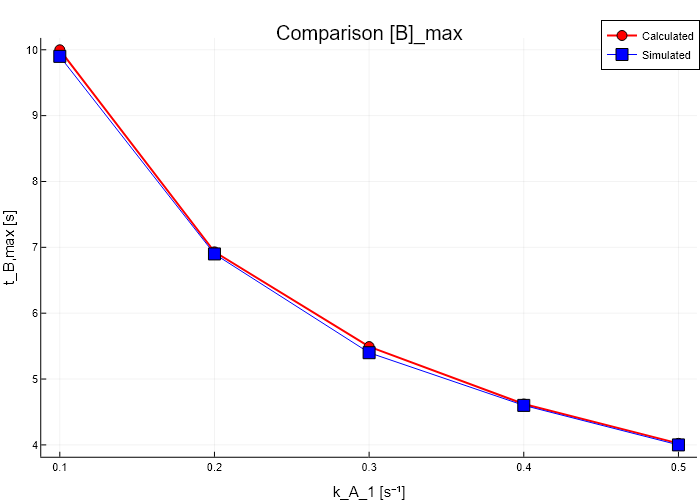

In [8]:
using CSV
using DataFrames
using Plots

function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    C_0 = 0.0         # mol/L
    k_a_1 = 0.1       # s^-1
    k_a_2 = 0.0       # s^-1
    k_b_1 = 0.1       # s^-1
    k_b_2 = 0.0       # s^-1
    delta_t = 0.1    # s
    T = 50            # s
    delta_k = 0.1     # s^-1
    num_steps = 5

    
    k_a_1_points = []
    t_max_sim = []
    t_max_calc = []

    results_str = "\n" * "="^70 * "\n"
    results_str *= rpad("k_A1", 8) * " | " * rpad("t_max(Sim)", 12) * " | " * rpad("t_max(Calc)", 12) * " | " * rpad("B_max(Sim)", 12) * " | " * rpad("B_max(Calc)", 12) * "\n"
    results_str *= "-"^70 * "\n"

    for step in 0:(num_steps-1)
        t_array = []
        B_array = []
        
        A = A_0 
        B = B_0;
        C = C_0 
        t = 0.0
        k_a_1_it = k_a_1 + step * delta_k
        
        while t <= T
            push!(t_array, t)
            push!(B_array, B)
            
            dA = (-k_a_1_it * A + k_a_2 * B) * delta_t
            dB = (k_a_1_it * A + k_b_2 * C - k_b_1 * B - k_a_2 * B) * delta_t
            dC = (-k_b_2 * C + k_b_1 * B) * delta_t
            
            A += dA; 
            B += dB; 
            C += dC; 
            t += delta_t
        end

        max_idx = argmax(B_array)
        max_val_B = B_array[max_idx]
        max_time = t_array[max_idx]

        calc_t = 0.0
        calc_B = 0.0
        
        if step == 0
            calc_t = 1.0 / k_b_1
            calc_B = A_0 * exp(-1.0)
        else
            calc_t = log(k_b_1 / k_a_1_it) / (k_b_1 - k_a_1_it)
            calc_B = A_0 * (k_a_1_it / k_b_1)^(k_b_1 / (k_b_1 - k_a_1_it))
        end

        push!(k_a_1_points, k_a_1_it)
        push!(t_max_sim, max_time)
        push!(t_max_calc, calc_t)

        r_ka   = rpad(string(round(k_a_1_it, digits=1)), 8)
        r_tsim = rpad(string(round(max_time, digits=2)), 12)
        r_tcal = rpad(string(round(calc_t, digits=2)), 12)
        r_bsim = rpad(string(round(max_val_B, digits=4)), 12)
        r_bcal = rpad(string(round(calc_B, digits=4)), 12)
        
        results_str *= r_ka * " | " * r_tsim * " | " * r_tcal * " | " * r_bsim * " | " * r_bcal * "\n"
    end
    results_str *= "="^70 * "\n"
    
    println(results_str)
    flush(stdout)

    plot(
        k_a_1_points, 
        t_max_calc, 
        label="Calculated", 
        linewidth=2, 
        color=:red,
        xlabel="k_A_1 [s⁻¹]",
        ylabel=" t_B,max [s]",
        title="Comparison [B]_max",
        marker=:circle,
        markersize=5
    )
    
    plot!(
        k_a_1_points, 
        t_max_sim, 
        label="Simulated", 
        color=:blue, 
        markersize=6,
        marker=:square
    )

end

kinetics_simulation()


If $k_{a_1} \rightarrow k_{b_1}$ 

$$B = \frac{k_a [A]_0}{k_b-k_a}(e^{-k_at} - e^{-k_bt}) = \frac{0}{0}$$

So we define a tiny difference that shrinks to zero as $k_{a_1} \rightarrow k_{b_1}$
$$k_{a_1} = k_{b_1} + \Delta k$$

$$e^{-k_{a_1} t} = e^{-(k_{b_1} + \Delta k)t} = e^{-k_{b_1}} e^{-\Delta kt}$$

Using a Taylor series expansion on $e^{-\Delta kt}$, $(e^x = 1 + x + \frac{x^2}{2!}+...)$

$$e^{-\Delta kt} \approx 1 - (\Delta kt) + \frac{(\Delta kt)^2}{2} + ...$$

First two terms are enough given that $\Delta k$ is so small

$$e^{-k_{a_1} t} \approx e^{-k_{b_1}t} (1 - \Delta k t)$$

$$B = \frac{k_a [A]_0}{k_b-(k_{b_1} + \Delta k)}(e^{-k_{b_1}t} (1 - \Delta k t) - e^{-k_bt})$$

$$B = \frac{k_a [A]_0}{-\Delta k}(-\Delta k t e^{-k_bt})$$

$$B = k_a [A]_0( t e^{-k_bt})$$

$$\frac{dB}{dt} = k_a [A]_0 (e^{-k_bt} - k_b e^{-k_bt} t) = 0$$

$$k_a [A]_0 e^{-k_bt}(1 - k_b t) = 0$$

$$(1 - k_b t) = 0$$

$$t_{max} = \frac{1}{k_b}$$

$k$'s are equal as the limit is approached. So for $k$ = 0.1:

$$t_{max} = 10 \hspace{0.10cm} s$$

$$B_{max} = 0.3679 \hspace{0.10cm} \text{mol/L}$$

***